# Assignment 2: Clustering Bank Marketing Customers (K-means vs Agglomerative)

## Introduction
In this assignment I apply unsupervised learning to the Bank Marketing dataset from the UCI Machine Learning Repository (Moro, Cortez & Rita, 2014). The data comes from direct marketing phone campaigns run by a Portuguese bank. Each row is a client, with numeric features (like age and account balance) and categorical features (like job, marital status and education). I am using the bank.csv file, which is a 10% random sample of the full dataset.

The dataset also has a label, y, which says whether the client subscribed to a term deposit (yes/no). Since this is unsupervised learning, I do not use y to build the clusters. I only use it at the end to calculate evaluation metrics.

My goal is to find natural customer segments and compare two clustering methods.

My steps:
- Load the data and clean it (missing/unknown values, encoding, scaling)
- Explore the data (EDA)
- Apply K-means and choose the number of clusters with the elbow method and silhouette score
- Apply Agglomerative Clustering and draw a dendrogram
- Visualize and profile the clusters from both methods
- Compare both methods with homogeneity, completeness and Adjusted Rand Index (ARI)
- Discuss the strengths and weaknesses of each method

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, homogeneity_score,
                             completeness_score, adjusted_rand_score)
from sklearn.metrics.cluster import contingency_matrix
from scipy.cluster.hierarchy import dendrogram, linkage

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Dataset

In [2]:
bank_df = pd.read_csv("bank.csv", sep=";")

In [3]:
print("Shape:", bank_df.shape)


Shape: (4521, 17)


In [4]:
display(bank_df.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [5]:
bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB


### Interpretation – Loading the Dataset
- The dataset has 4,521 rows (clients) and 17 columns: 16 features plus the label y.
- 7 columns are numeric (age, balance, day, duration, campaign, pdays, previous) and 9 are categorical (job, marital, education, default, housing, loan, contact, month, poutcome). This gives me the mix of numerical and categorical features the assignment asks for.
- The categorical columns show as str, which is the new text data type in pandas 3.0. It works the same as object.
- info() shows no null values, but the first rows already show the word "unknown" in poutcome and contact. This dataset stores missing information as "unknown" instead of empty cells, so I need to check for it separately.
- pdays = -1 means the client was never contacted in a previous campaign. It is a code, not a real number of days.
- y (subscribed to a term deposit: yes/no) is the label. I will keep it aside and only use it for evaluation.

## 3. Data Cleaning – Hidden Missing Values

In [6]:
cat_cols = bank_df.select_dtypes(include="str").columns.drop("y").tolist()
num_cols = bank_df.select_dtypes(include="number").columns.tolist()
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numeric: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [7]:
unknown_counts = (bank_df[cat_cols] == "unknown").sum()
unknown_pct = (unknown_counts / len(bank_df) * 100).round(2)
display(pd.DataFrame({"unknown_count": unknown_counts, "unknown_%": unknown_pct}))

,unknown_count,unknown_%
job,38,0.84
marital,0,0.00
education,187,4.14
default,0,0.00
housing,0,0.00
loan,0,0.00
contact,1324,29.29
month,0,0.00
poutcome,3705,81.95


In [8]:
print("pdays = -1 (never contacted):", (bank_df["pdays"] == -1).sum())
print("Duplicate rows:", bank_df.duplicated().sum())

pdays = -1 (never contacted): 3705
Duplicate rows: 0


In [9]:
print("\nLabel y:")
print(bank_df["y"].value_counts())
print(bank_df["y"].value_counts(normalize=True).round(3))


Label y:
y
no     4000
yes     521
Name: count, dtype: int64
y
no     0.885
yes    0.115
Name: proportion, dtype: float64


### Interpretation – Hidden Missing Values and Label
- No column has empty cells, but some use the word "unknown" as a missing value:
  - job: 38 rows (0.84%) and education: 187 rows (4.14%). These are small, so I keep "unknown" as its own category instead of guessing values.
  - contact: 1,324 rows (29.29%). This column only says whether the client was called on a cellular or a landline phone, which does not describe the customer, so I drop it.
  - poutcome: 3,705 rows (81.95%). This is exactly the same number as pdays = -1, so these clients are not missing data. They were never contacted in a previous campaign. I rename "unknown" to "not_contacted".
- There are no duplicate rows.
- The label y is imbalanced: 4,000 clients (88.5%) said no and only 521 (11.5%) said yes. I only use y for the evaluation metrics at the end. Because most clients are "no", I expect the clusters to not match the yes/no split very closely.

## 4. Data Cleaning – Feature Selection

In [10]:
y_true = (bank_df["y"] == "yes").astype(int)


In [11]:
drop_cols = ["day", "month", "duration", "contact", "pdays", "y"]
clean_df = bank_df.drop(columns=drop_cols).copy()

In [12]:
clean_df["poutcome"] = clean_df["poutcome"].replace("unknown", "not_contacted")

In [13]:
num_features = ["age", "balance", "campaign", "previous"]
cat_features = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]

print("Clean shape:", clean_df.shape)
print("poutcome values:", clean_df["poutcome"].value_counts().to_dict())
print("y_true counts:", y_true.value_counts().to_dict())
display(clean_df.head())

Clean shape: (4521, 11)
poutcome values: {'not_contacted': 3705, 'failure': 490, 'other': 197, 'success': 129}
y_true counts: {0: 4000, 1: 521}


,age,job,marital,education,default,balance,housing,loan,campaign,previous,poutcome
0,30,unemployed,married,primary,no,1787,no,no,1,0,not_contacted
1,33,services,married,secondary,no,4789,yes,yes,1,4,failure
2,35,management,single,tertiary,no,1350,yes,no,1,1,failure
3,30,management,married,tertiary,no,1476,yes,yes,4,0,not_contacted
4,59,blue-collar,married,secondary,no,0,yes,no,1,0,not_contacted


### Interpretation – Feature Selection
- After cleaning, I have 4,521 clients and 11 features: 4 numeric (age, balance, campaign, previous) and 7 categorical (job, marital, education, default, housing, loan, poutcome).
- I removed day, month and contact because they describe the phone call, not the customer. I removed pdays because poutcome already shows whether a client was contacted before. I removed duration because the call length is only known after the call, so it is not a real customer trait and is strongly linked to the outcome.
- poutcome now shows 3,705 clients who were not contacted before, 490 failures, 197 other, and only 129 successes from the previous campaign.
- The label is stored separately as y_true (1 = yes, 0 = no) with 4,000 no and 521 yes. It will not be used to build the clusters.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Numeric Features

In [14]:
display(clean_df[num_features].describe().round(2))

,age,balance,campaign,previous
count,4521.00,4521.00,4521.00,4521.00
mean,41.17,1422.66,2.79,0.54
std,10.58,3009.64,3.11,1.69
min,19.00,-3313.00,1.00,0.00
25%,33.00,69.00,1.00,0.00
50%,39.00,444.00,2.00,0.00
75%,49.00,1480.00,3.00,0.00
max,87.00,71188.00,50.00,25.00


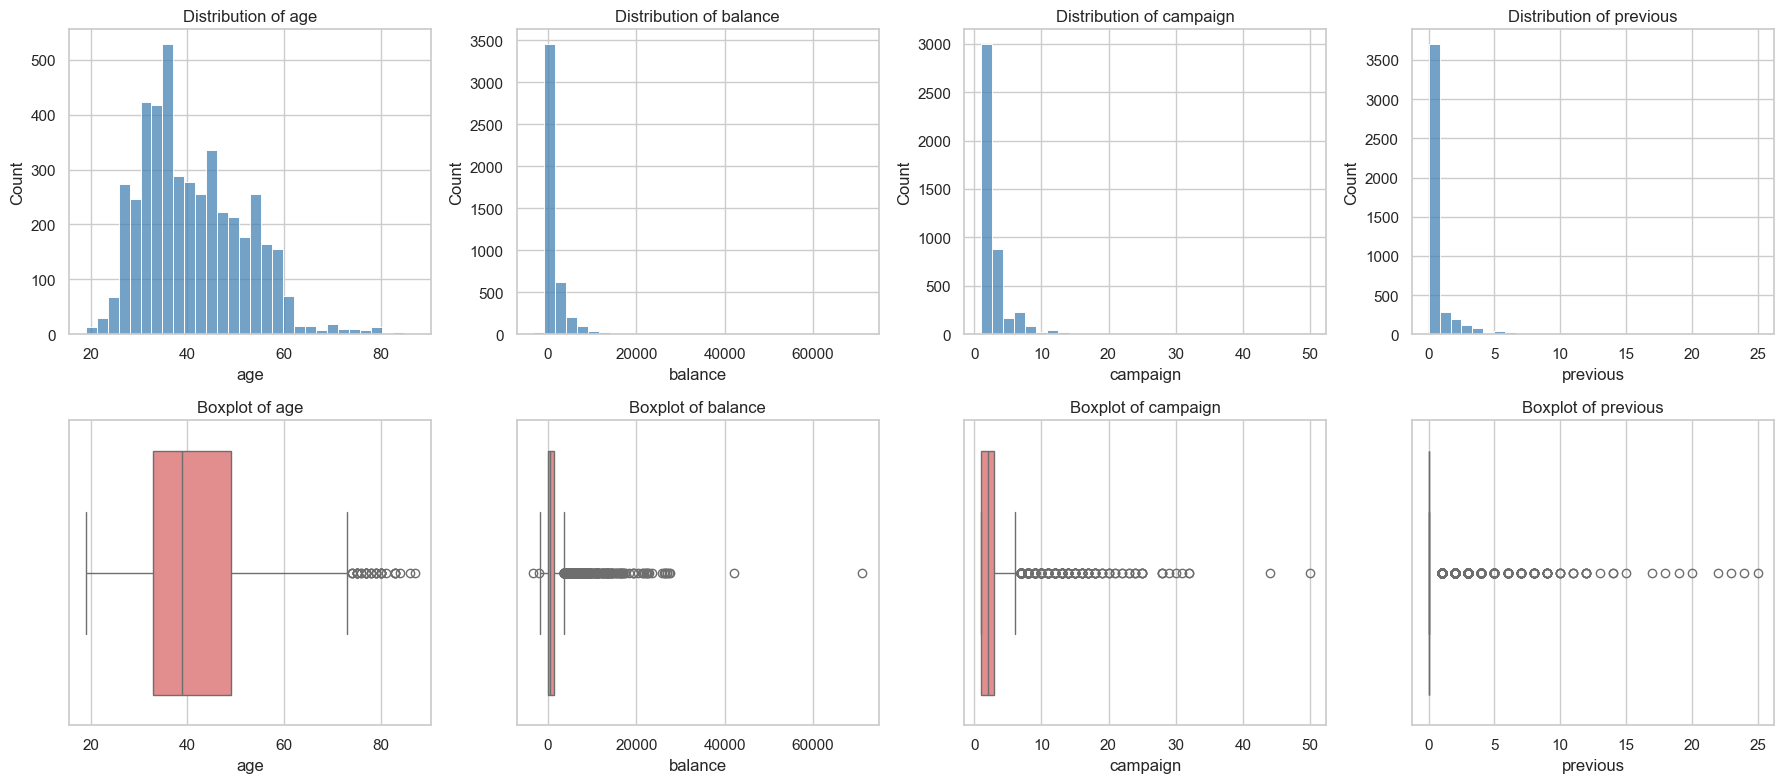

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(num_features):
    sns.histplot(clean_df[col], bins=30, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(x=clean_df[col], ax=axes[1, i], color="lightcoral")
    axes[1, i].set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

### Interpretation – Numeric Features
- age ranges from 19 to 87, with a median of 39. Most clients are between 33 and 49. The shape is close to normal with a few older outliers above about 73, which is reasonable for bank customers.
- balance is very right-skewed. The median balance is €444, but the mean is €1,423 because a few clients have very large balances (up to €71,188). Some clients have negative balances (down to -€3,313), which means overdrawn accounts. The boxplot shows many outliers on the high side.
- campaign (number of calls in this campaign) has a median of 2, but some clients were called up to 50 times. This is also right-skewed with many outliers.
- previous (number of contacts before this campaign) is 0 for at least 75% of clients, which matches the 3,705 clients who were never contacted before. A small group was contacted many times (up to 25).
- K-means and Agglomerative clustering use distances, so these long tails and outliers could pull the clusters toward a few extreme clients. Before scaling, I will apply a log transform to balance, campaign and previous to reduce the skew.

### 5.2 Categorical Features

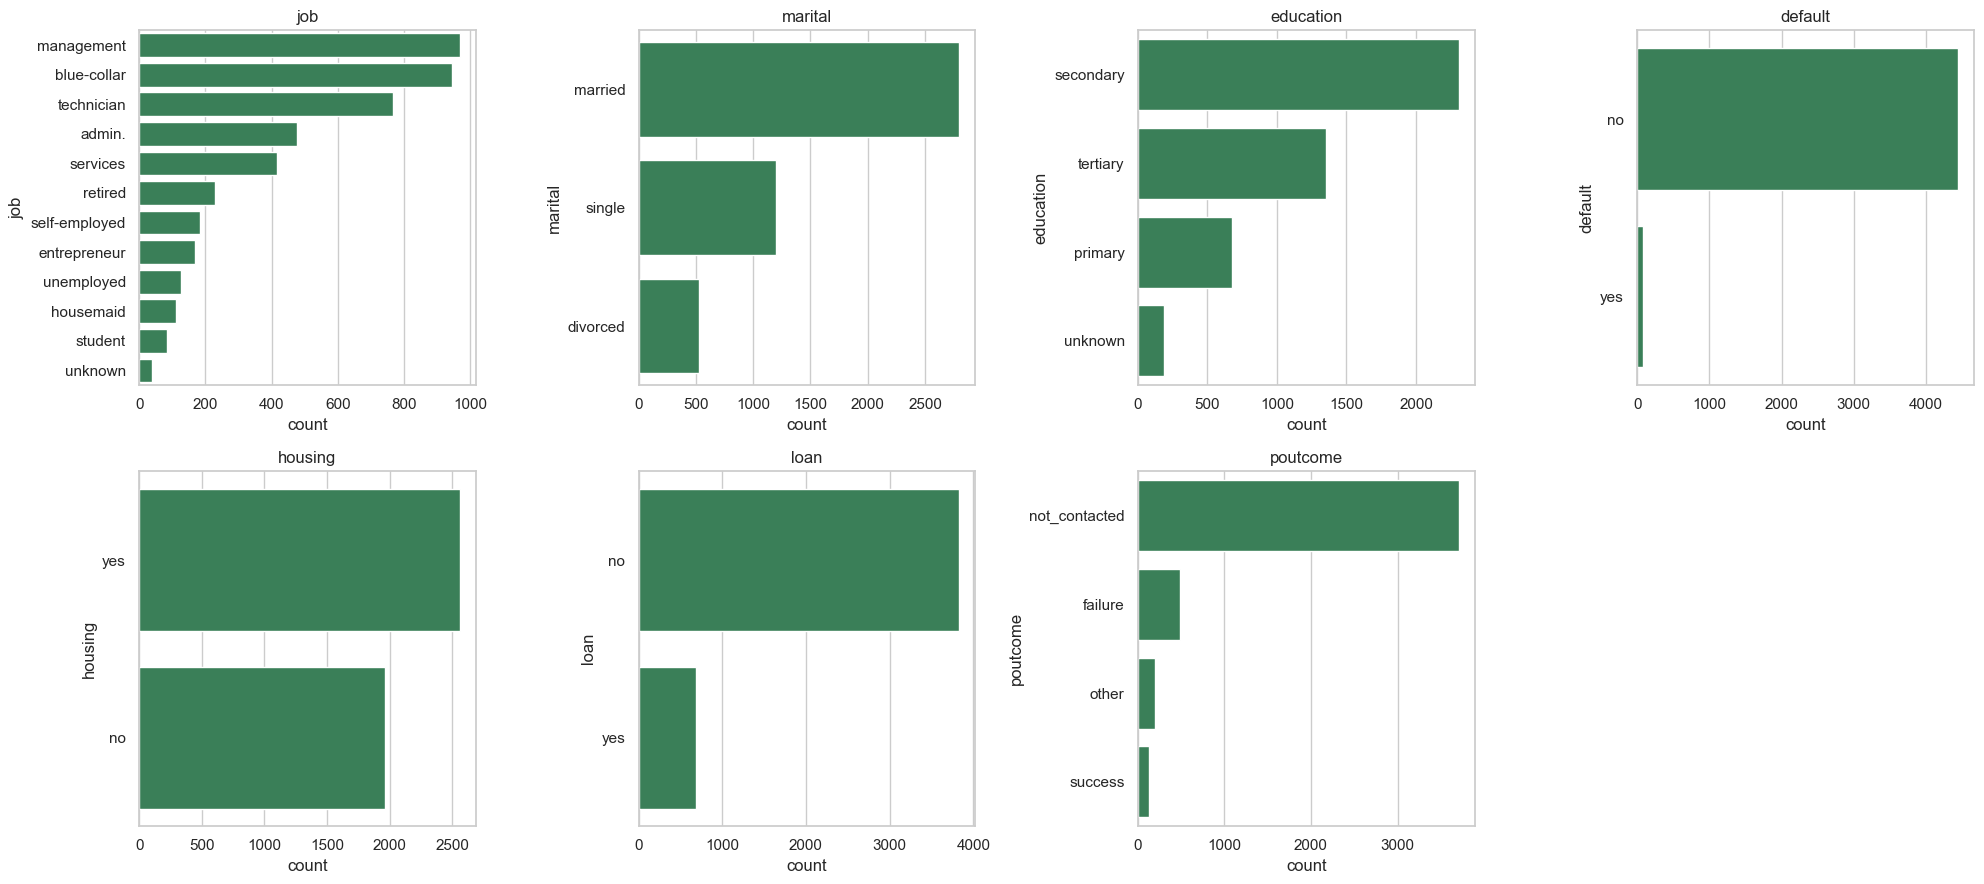

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
for i, col in enumerate(cat_features):
    order = clean_df[col].value_counts().index
    sns.countplot(y=clean_df[col], order=order, ax=axes[i], color="seagreen")
    axes[i].set_title(f"{col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation – Categorical Features
- job: the most common jobs are management, blue-collar and technician, followed by admin. and services. Groups like students, housemaids and unemployed are small, and only a few clients have an unknown job.
- marital: most clients are married, then single, with divorced being the smallest group.
- education: secondary education is the most common, followed by tertiary and primary. A small group is unknown.
- default: almost all clients have no credit in default. Only a very small number say yes, so this feature will not help much to separate clients into groups.
- housing: this is fairly balanced, with a bit more clients having a housing loan than not.
- loan: most clients do not have a personal loan.
- poutcome: most clients were not contacted before. Among those who were, failure is the most common outcome and success is the rarest (129 clients).
- After one-hot encoding, these 7 categorical columns will turn into many 0/1 columns, while there are only 4 numeric columns. This means the categorical features will have a bigger influence on the distances used by the clustering methods.

## 6. Preprocessing – Log Transform, Encoding and Scaling

In [17]:
X = clean_df.copy()
X["balance"] = np.sign(X["balance"]) * np.log1p(np.abs(X["balance"]))
X["campaign"] = np.log1p(X["campaign"])
X["previous"] = np.log1p(X["previous"])


In [18]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
])

In [19]:
X_prep = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

In [20]:
print("Shape after preprocessing:", X_prep.shape)
display(pd.DataFrame(X_prep, columns=feature_names).head())
display(pd.DataFrame(X_prep[:, :4], columns=num_features).describe().round(2))

Shape after preprocessing: (4521, 30)


,num__age,num__balance,num__campaign,num__previous,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,cat__job_management,cat__job_retired,cat__job_self-employed,cat__job_services,cat__job_student,cat__job_technician,cat__job_unemployed,cat__job_unknown,cat__marital_divorced,cat__marital_married,cat__marital_single,cat__education_primary,cat__education_secondary,cat__education_tertiary,cat__education_unknown,cat__default_yes,cat__housing_yes,cat__loan_yes,cat__poutcome_failure,cat__poutcome_not_contacted,cat__poutcome_other,cat__poutcome_success
0,-1.056270,0.677117,-0.913341,-0.423759,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.772583,0.936703,-0.913341,2.662687,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
2,-0.583458,0.603293,-0.913341,0.905501,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,-1.056270,0.626781,0.862295,-0.423759,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
4,1.686036,-1.295615,-0.913341,-0.423759,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


,age,balance,campaign,previous
count,4521.00,4521.00,4521.00,4521.00
mean,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.10,-3.43,-0.91,-0.42
25%,-0.77,-0.18,-0.91,-0.42
50%,-0.21,0.31,-0.13,-0.42
75%,0.74,0.63,0.43,-0.42
max,4.33,1.65,5.36,5.82


### Interpretation – Preprocessing
- After preprocessing, I have 4,521 rows and 30 columns: 4 scaled numeric columns and 26 one-hot encoded categorical columns.
- For yes/no columns (default, housing, loan), only one column was kept (for example cat__housing_yes), because the "no" column would just repeat the same information.
- The 4 numeric columns now all have a mean of 0 and a standard deviation of 1, so no single feature dominates the distances because of its units.
- The log transform reduced the skew a lot. Balance used to range up to €71,188, but after the transform and scaling its maximum is only 1.65, so the few very rich clients no longer pull the clusters toward them. Overdrawn clients (negative balance) are now at the low end, down to -3.43.
- previous is still the same value for 25%, 50% and 75% of clients because most clients have 0 previous contacts.
- The data is now fully numeric and ready for distance-based clustering.

## 7. K-means – Choosing the Number of Clusters

In [21]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_prep)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_prep, labels))

k_results = pd.DataFrame({"k": list(k_range), "inertia": inertias, "silhouette": sil_scores})
print(k_results.round(4).to_string(index=False))

 k    inertia  silhouette
 2 25605.6087      0.2402
 3 22531.0532      0.2058
 4 20063.6737      0.1570
 5 18111.5833      0.1601
 6 17270.7213      0.1365
 7 16692.9326      0.1251
 8 16168.2313      0.1196
 9 15735.3179      0.1152
10 15405.2670      0.1152


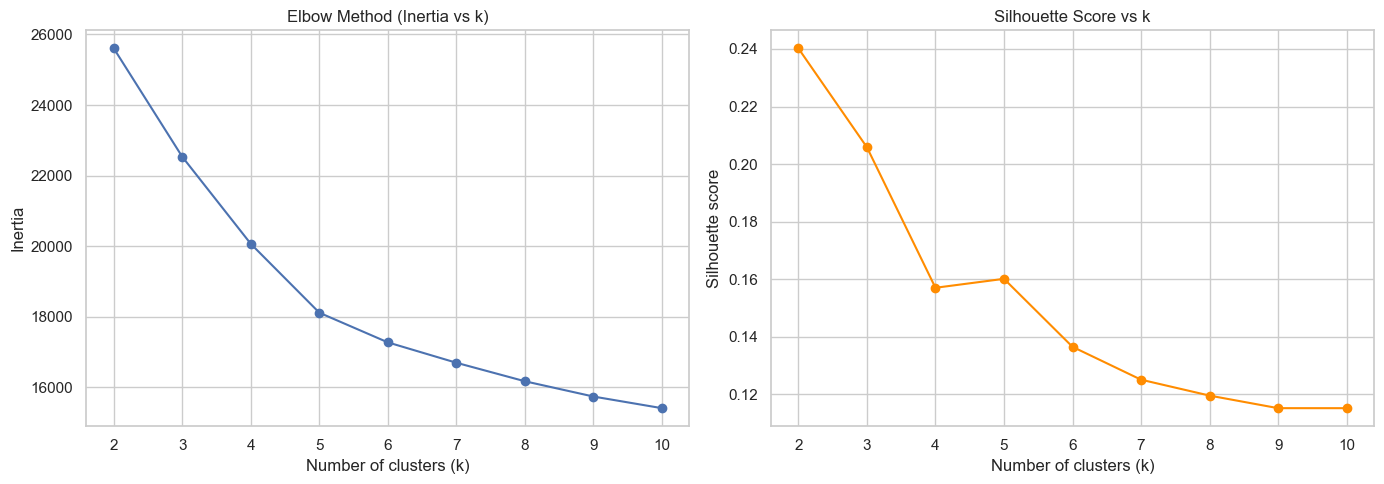

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, marker="o")
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_range, sil_scores, marker="o", color="darkorange")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

### Interpretation – Choosing k
- Elbow method: inertia drops quickly from k = 2 to k = 5 (about 2,000 to 3,000 per step). After k = 5 the drop gets much smaller (only 841 from k = 5 to k = 6), so the elbow is at k = 5.
- Silhouette score: the highest score is at k = 2 (0.240). It then drops, but k = 5 (0.160) is slightly higher than k = 4 (0.157), so k = 5 is a local peak.
- I chose k = 5 because both the elbow and the silhouette bump point to it, and 5 segments are more useful for a marketing team than only 2 very broad groups.
- All silhouette scores are low (below 0.25). This means the clusters overlap and are not strongly separated, which is common with real customer data that mixes numeric and categorical features. Customers do not fall into perfectly separate groups.

## 8. K-means Clustering (k = 5)

In [23]:
best_k = 5
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X_prep)

profile_df = clean_df.copy()
profile_df["km_cluster"] = km_labels

print("Cluster sizes:")
print(profile_df["km_cluster"].value_counts().sort_index())

Cluster sizes:
km_cluster
0    1559
1    1058
2     582
3     697
4     625
Name: count, dtype: int64


In [24]:
num_profile = profile_df.groupby("km_cluster").agg(
    age_mean=("age", "mean"),
    balance_median=("balance", "median"),
    campaign_mean=("campaign", "mean"),
    previous_mean=("previous", "mean"),
).round(2)
display(num_profile)


,age_mean,balance_median,campaign_mean,previous_mean
km_cluster,,,,
0,34.16,628.0,1.80,0.00
1,54.01,714.5,1.98,0.07
2,38.87,-48.0,2.24,0.11
3,39.63,680.0,1.92,3.29
4,40.79,389.0,8.16,0.03


In [25]:
cat_profile = profile_df.groupby("km_cluster").agg(
    top_job=("job", lambda s: s.value_counts().index[0]),
    top_marital=("marital", lambda s: s.value_counts().index[0]),
    top_education=("education", lambda s: s.value_counts().index[0]),
    housing_yes_pct=("housing", lambda s: round((s == "yes").mean() * 100, 1)),
    loan_yes_pct=("loan", lambda s: round((s == "yes").mean() * 100, 1)),
    contacted_before_pct=("poutcome", lambda s: round((s != "not_contacted").mean() * 100, 1)),
)
display(cat_profile)

,top_job,top_marital,top_education,housing_yes_pct,loan_yes_pct,contacted_before_pct
km_cluster,,,,,,
0,management,married,secondary,62.1,14.0,0.1
1,blue-collar,married,secondary,39.2,14.9,5.9
2,blue-collar,married,secondary,64.6,22.9,6.7
3,management,married,secondary,65.4,11.8,100.0
4,management,married,secondary,55.0,16.0,2.7


### Interpretation – K-means Cluster Profiles (k = 5)
- Cluster 0 – Young new prospects (1,559 clients, 34.5%): the youngest group (average age 34) with a median balance of €628. Almost none of them (0.1%) were contacted in a previous campaign, so they are new to the bank's marketing.
- Cluster 1 – Older settled savers (1,058 clients, 23.4%): the oldest group (average age 54) with the highest median balance (€714.50). They have the lowest share of housing loans (39.2%), which fits people who may have already paid off their homes.
- Cluster 2 – Financially stretched borrowers (582 clients, 12.9%): the median balance is -€48, so at least half of these clients are overdrawn. They also have the highest share of personal loans (22.9%) and many housing loans (64.6%).
- Cluster 3 – Past-campaign contacts (697 clients, 15.4%): every client in this group (100%) was contacted in an earlier campaign, with an average of 3.29 previous contacts. This is the bank's "warm" audience.
- Cluster 4 – Heavily chased (625 clients, 13.8%): these clients were called about 8.16 times in this campaign, compared with about 2 calls in the other clusters.

The most common job, marital status and education are almost the same in every cluster (mostly married, secondary education, management or blue-collar). This shows that the clusters were mainly formed by the numeric features (age, balance, previous contacts and number of calls), not by the categorical ones. Even though there are 26 one-hot columns, each one is mostly 0, so it adds less to the distance than a scaled numeric feature.

From a marketing view, these segments suggest different strategies: nurture campaigns for young prospects, savings or investment offers for older savers, careful (or no) offers for stretched borrowers, re-engagement for past contacts, and a call limit for the heavily chased group to avoid annoying them.

### 8.1 Visualizing the K-means Clusters

In [26]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_prep)
print("Explained variance by 2 components:", pca.explained_variance_ratio_.round(3),
      "| Total:", pca.explained_variance_ratio_.sum().round(3))

Explained variance by 2 components: [0.189 0.169] | Total: 0.358


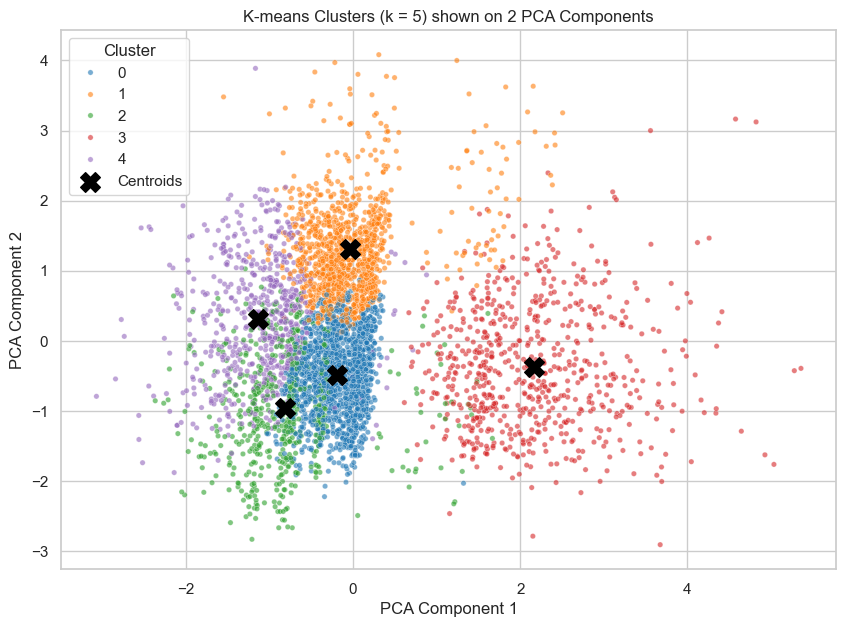

In [27]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels, palette="tab10", s=15, alpha=0.6)
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.title("K-means Clusters (k = 5) shown on 2 PCA Components")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.show()

### Interpretation – K-means Clusters on PCA
- I used PCA (Principal Component Analysis) to squash the 30 columns into 2 components only to draw the clusters. The 2 components keep about __% of the total information (from my explained variance output), so this plot is a simplified view.
- Cluster 3 (past-campaign contacts, red) is clearly separated on the right side. PCA Component 1 mainly captures previous contacts, so this group stands out the most.
- Cluster 1 (older settled savers, orange) sits at the top of the plot, so PCA Component 2 is mostly linked to age.
- Clusters 0 (young new prospects), 2 (financially stretched borrowers) and 4 (heavily chased) overlap on the left. They differ mainly in balance and number of calls, which this 2D view cannot fully show. This overlap matches the low silhouette score (0.160).
- The black X marks show the centroids, and each one sits in the middle of its group, so K-means placed the cluster centres correctly.

## 9. Agglomerative Clustering

### 9.1 Dendrogram

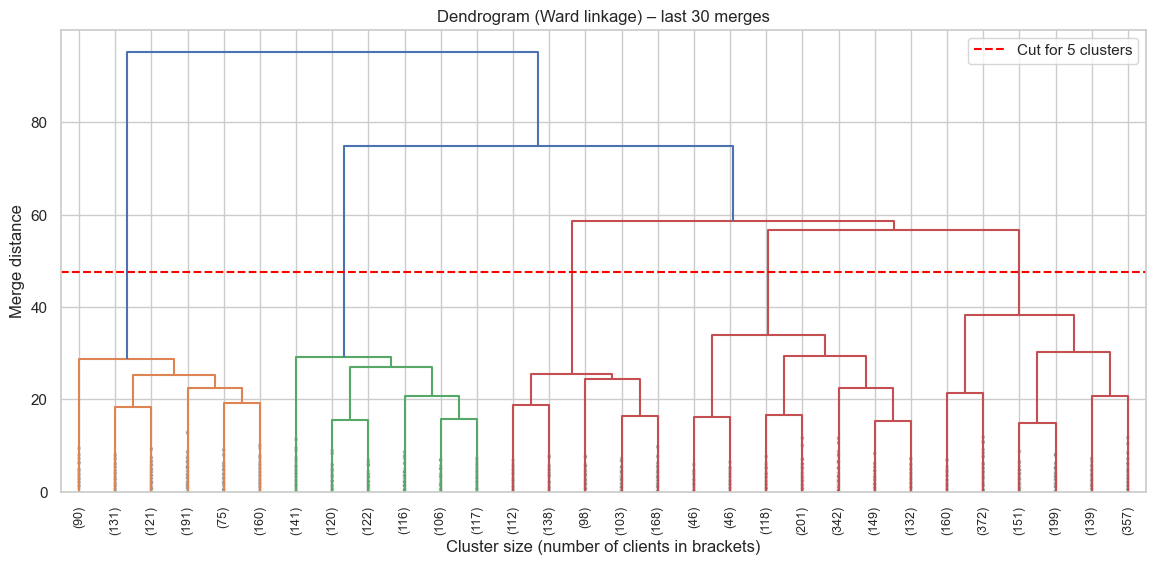

Merge distances of the last 6 merges: [34.   38.31 56.76 58.64 74.81 95.2 ]


In [28]:
linkage_matrix = linkage(X_prep, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)
plt.axhline(y=(linkage_matrix[-5, 2] + linkage_matrix[-4, 2]) / 2,
            color="red", linestyle="--", label="Cut for 5 clusters")
plt.title("Dendrogram (Ward linkage) – last 30 merges")
plt.xlabel("Cluster size (number of clients in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.show()

print("Merge distances of the last 6 merges:", linkage_matrix[-6:, 2].round(2))

### 9.2 Agglomerative Clusters (k = 5)

In [29]:
agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
agg_labels = agg.fit_predict(X_prep)
profile_df["agg_cluster"] = agg_labels

print("Agglomerative cluster sizes:")
print(profile_df["agg_cluster"].value_counts().sort_index())

Agglomerative cluster sizes:
agg_cluster
0    1378
1    1034
2     722
3     619
4     768
Name: count, dtype: int64


In [30]:
agg_profile = profile_df.groupby("agg_cluster").agg(
    age_mean=("age", "mean"),
    balance_median=("balance", "median"),
    campaign_mean=("campaign", "mean"),
    previous_mean=("previous", "mean"),
    housing_yes_pct=("housing", lambda s: round((s == "yes").mean() * 100, 1)),
    loan_yes_pct=("loan", lambda s: round((s == "yes").mean() * 100, 1)),
    contacted_before_pct=("poutcome", lambda s: round((s != "not_contacted").mean() * 100, 1)),
).round(2)
display(agg_profile)

,age_mean,balance_median,campaign_mean,previous_mean,housing_yes_pct,loan_yes_pct,contacted_before_pct
agg_cluster,,,,,,,
0,35.05,662.0,1.77,0.00,62.0,14.4,0.0
1,51.40,761.0,2.01,0.10,44.5,13.9,4.6
2,39.96,0.0,2.96,0.00,56.8,21.1,0.0
3,40.77,529.0,7.14,0.00,51.7,15.7,0.0
4,39.83,602.0,2.03,3.05,66.9,12.9,100.0


In [31]:
print("K-means vs Agglomerative (rows = K-means, columns = Agglomerative):")
display(pd.crosstab(profile_df["km_cluster"], profile_df["agg_cluster"]))
print(f"Silhouette – K-means: {silhouette_score(X_prep, km_labels):.4f} | "
      f"Agglomerative: {silhouette_score(X_prep, agg_labels):.4f}")

K-means vs Agglomerative (rows = K-means, columns = Agglomerative):


agg_cluster,0,1,2,3,4
km_cluster,,,,,
0,1191,203,55,109,1
1,136,774,58,64,26
2,11,6,523,3,39
3,0,12,0,0,685
4,40,39,86,443,17


Silhouette – K-means: 0.1601 | Agglomerative: 0.1062


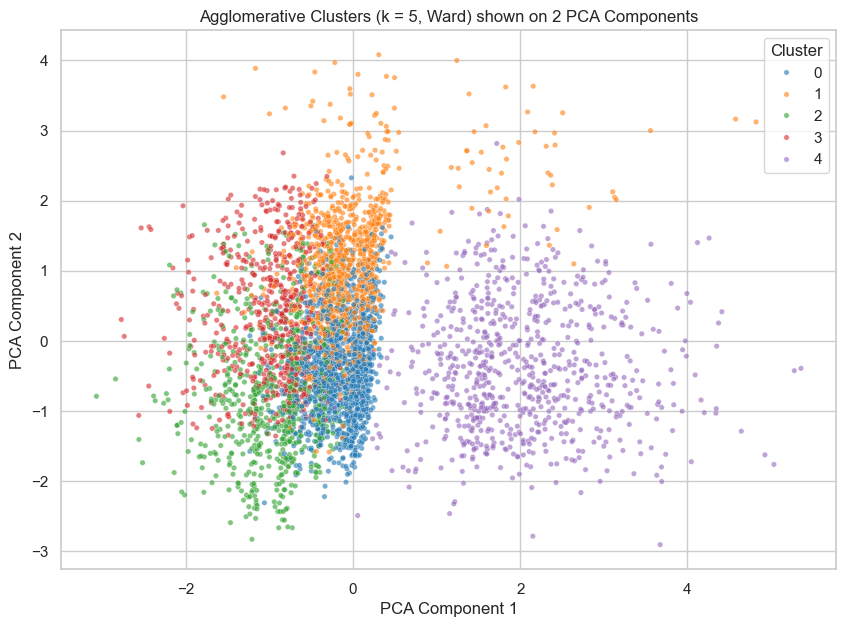

In [32]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels, palette="tab10", s=15, alpha=0.6)
plt.title("Agglomerative Clusters (k = 5, Ward) shown on 2 PCA Components")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.show()

### Interpretation – Agglomerative Clusters and Comparison with K-means
Agglomerative Clustering (Ward linkage, k = 5) found the same 5 customer segments as K-means, with different cluster numbers:
- Cluster 0 – Young new prospects (1,378 clients): average age 35, median balance €662, never contacted before.
- Cluster 1 – Older settled savers (1,034 clients): the oldest group (average age 51.4), highest median balance (€761) and fewest housing loans (44.5%).
- Cluster 2 – Low-balance borrowers (722 clients): median balance €0 and the most personal loans (21.1%). This group is bigger than the K-means version because it also includes clients with zero balance, not only overdrawn ones.
- Cluster 3 – Heavily chased (619 clients): about 7.14 calls in this campaign, far more than the other groups.
- Cluster 4 – Past-campaign contacts (768 clients): 100% were contacted before, with about 3 previous contacts on average.

Comparison with K-means:
- The crosstab shows strong agreement. 3,616 of 4,521 clients (80%) land in the matching segment in both methods.
- The past-campaign contacts segment is almost identical (685 of 697 K-means clients, 98%), so it is the most clearly separated group. This matches the PCA plots, where it sits alone on the right side.
- The young prospects, older savers and heavily chased segments agree 71% to 76%. These groups overlap more, so the two methods draw their borders slightly differently.
- K-means has a higher silhouette score (0.160) than Agglomerative (0.106), so K-means produced tighter and better-separated clusters. This makes sense because K-means directly tries to minimize the distance between each client and its cluster centre.
- The Agglomerative PCA plot looks very similar to the K-means plot: past-campaign contacts on the right, older savers at the top, and the other three groups overlapping on the left.

## 10. Evaluation Metrics

In [33]:
metrics_table = pd.DataFrame({
    "Metric": ["Homogeneity", "Completeness", "Adjusted Rand Index (ARI)", "Silhouette"],
    "K-means": [homogeneity_score(y_true, km_labels),
                completeness_score(y_true, km_labels),
                adjusted_rand_score(y_true, km_labels),
                silhouette_score(X_prep, km_labels)],
    "Agglomerative": [homogeneity_score(y_true, agg_labels),
                      completeness_score(y_true, agg_labels),
                      adjusted_rand_score(y_true, agg_labels),
                      silhouette_score(X_prep, agg_labels)],
})
print(metrics_table.round(4).to_string(index=False))

                   Metric  K-means  Agglomerative
              Homogeneity   0.0322         0.0288
             Completeness   0.0075         0.0066
Adjusted Rand Index (ARI)   0.0053         0.0048
               Silhouette   0.1601         0.1062


In [34]:
print("\nContingency matrix – K-means (rows: y 0=no, 1=yes | columns: clusters)")
display(pd.DataFrame(contingency_matrix(y_true, km_labels), index=["no", "yes"]))




Contingency matrix – K-means (rows: y 0=no, 1=yes | columns: clusters)


,0,1,2,3,4
no,1403,930,543,540,584
yes,156,128,39,157,41


In [35]:
rate_table = pd.DataFrame({
    "K-means subscribe %": profile_df.assign(y=y_true).groupby("km_cluster")["y"].mean().mul(100).round(1),
    "Agglomerative subscribe %": profile_df.assign(y=y_true).groupby("agg_cluster")["y"].mean().mul(100).round(1),
})
print("Overall subscribe rate:", round(y_true.mean() * 100, 1), "%")
display(rate_table)

Overall subscribe rate: 11.5 %


,K-means subscribe %,Agglomerative subscribe %
0,10.0,9.9
1,12.1,11.0
2,6.7,6.9
3,22.5,8.6
4,6.6,21.9


### Interpretation – Evaluation Metrics
- Homogeneity is very low for both methods (K-means 0.0322, Agglomerative 0.0288). Every cluster contains a mix of clients who said yes and no, so no cluster is "pure".
- Completeness is even lower (0.0075 and 0.0066). The 521 clients who subscribed are spread across all 5 clusters instead of being grouped together. For example, K-means cluster 0 alone has 156 of them. With 5 clusters and only 2 classes, completeness is naturally limited.
- The Adjusted Rand Index (ARI) is about 0.005 for both, which is almost 0, so the clusters match the yes/no label no better than random grouping.
- K-means scores slightly higher than Agglomerative on every metric, including silhouette (0.160 vs 0.106), but the differences are very small.
- These low scores do not mean the clustering failed. The clusters group clients by age, balance and contact history, not by whether they will subscribe. Also, the label is imbalanced (only 11.5% yes), so there is no obvious yes group for the clusters to find.

### Subscription rate by segment
Even though the metrics are low, the segments show clear differences in how clients responded (overall rate: 11.5%):
- Past-campaign contacts subscribed at about 22% in both methods, about twice the average. This is the bank's best audience.
- Older settled savers (11–12%) and young new prospects (about 10%) are close to the average.
- Heavily chased clients (6.6% to 8.6%) and low-balance borrowers (about 7%) subscribed at roughly half the average rate. Calling the same client many times does not seem to work.
So the clusters are useful for marketing decisions, even if they do not match the yes/no label.

## 11. Strengths and Weaknesses of Each Method

### K-means
Strengths:
- It scored slightly better on every metric: homogeneity 0.0322, completeness 0.0075, ARI 0.0053 and silhouette 0.160 (vs 0.106 for Agglomerative), so its clusters were tighter and better separated.
- It is fast and scales well to large datasets. Fitting k = 2 to 10 with 10 restarts each took only seconds.
- It gives clear centroids, which make it easy to describe each segment, and it can assign new customers to a segment with predict().

Weaknesses:
- I had to choose k myself, and the elbow (k = 5) and silhouette (k = 2) pointed to different answers.
- It assumes round, similar-sized clusters and uses means, so it is sensitive to skew and outliers. I had to log-transform balance, campaign and previous first.
- It is not designed for categorical data. One-hot encoding works, but mixed data is not its natural fit.

### Agglomerative Clustering
Strengths:
- The dendrogram shows the full merge structure, so I could see that k = 2 (the biggest gap) and k = 5 (the second big gap) are both reasonable, without guessing.
- It has no random start, so it gives the same result every run.
- It found almost the same segments as K-means (80% agreement and 98% for the past-campaign contacts group), which confirms that these segments are real and not just a result of one algorithm.

Weaknesses:
- It had lower scores on all metrics, especially silhouette (0.106), so its cluster borders were less clean.
- It is slower and uses much more memory because it compares every pair of clients (4,521 × 4,521). It would struggle with the full 45,211-row dataset.
- It cannot assign new customers to an existing cluster. The whole tree would have to be rebuilt.
- Once two groups are merged, the merge cannot be undone, so an early bad merge stays in the final result.

### Both methods
- The label-based metrics are near 0 for both, because customer segments based on age, balance and contact history are not the same thing as the yes/no subscription outcome.

## Conclusion
I clustered 4,521 bank clients using 4 numeric and 7 categorical features after cleaning the hidden "unknown" values, log-transforming skewed columns, one-hot encoding and scaling. The elbow method pointed to k = 5, and both K-means and Agglomerative Clustering found the same 5 segments: young new prospects, older settled savers, low-balance borrowers, past-campaign contacts and heavily chased clients. K-means performed slightly better on every metric and is more practical for a bank because it is fast and can score new customers. The label-based metrics were close to 0 because the segments do not line up with the yes/no outcome, but the segments were still useful: past-campaign contacts subscribed at about twice the average rate, while heavily chased and low-balance clients subscribed at about half. A bank could use this to focus calls on warm contacts and set a limit on repeated calls.

Note: the instructions asked for a dataset with both numerical and categorical features, so I used the UCI Bank Marketing dataset (bank.csv) instead of the all-numeric examples. I used its label y only to calculate the evaluation metrics, not to build the clusters.